# Longest run of "high" windows: a complement to the Poisson count test

**Question.** The count test judges each window on its own, so a *long but modest* elevation is never flagged (see *Known Issues* in `PROJECT_STATUS.md`). Can the distribution of the **longest run** from Schilling (1990) catch it?

**Idea.** Mark each window "high" if its count is above the median. In normal traffic the marks behave like (biased) coin flips, so a long run of "high" windows is unlikely. Schilling gives the exact distribution of the longest run in *n* coin tosses with P(head) = *p*, plus a simple approximation.

**Reference.** M. F. Schilling, "The Longest Run of Heads", *The College Mathematics Journal* 21(3), 196–207 (1990).

**Contents**
1. The exact distribution, checked against the paper's Table 2
2. From counts to coin flips: the run test
3. Experiment A: detection power, count test vs run test
4. Experiment B: false alarms under over-dispersed (non-Poisson) traffic
5. Takeaways and next steps

## Setup

In [1]:
from pathlib import Path
from typing import NamedTuple, Optional
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import poisson

# Make the package importable from the repository root or from notebooks/.
repo_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
sys.path.insert(0, str(repo_root / "src"))

from poisson_log_analyzer import detect_spikes

plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": 0.25})

## 1. The exact distribution of the longest run

For *n* independent trials with success probability *p*, track the length of the current run. The state vector holds P(current run = *j* and no run of length *r* has occurred yet); one step either extends the run (probability *p*) or resets it. Probability that reaches length *r* is absorbed into the answer. This is an *O(n·r)* alternative to the recursions (1) and (4) in the paper.

The paper's large-*n* approximation (eq. 7) reduces to a closed form, which I read as `P(R_n ≤ x) ≈ exp(−n·q·p^(x+1))` with *q* = 1 − *p*. The check below shows it reproduces the paper's approximate column.

    x  paper exact  mine exact  paper approx  mine approx
  0-3        0.001       0.001         0.002        0.002
    4        0.033       0.033         0.042        0.042
    5        0.165       0.165         0.166        0.166
    6        0.257       0.257         0.248        0.248
    7        0.224       0.224         0.219        0.219
    8        0.146       0.146         0.146        0.146
    9        0.083       0.083         0.084        0.084
   10        0.044       0.044         0.045        0.045
   11        0.023       0.023         0.024        0.024
   12        0.011       0.011         0.012        0.012
  >12        0.012       0.011         0.012        0.012
Matches the paper's Table 2.


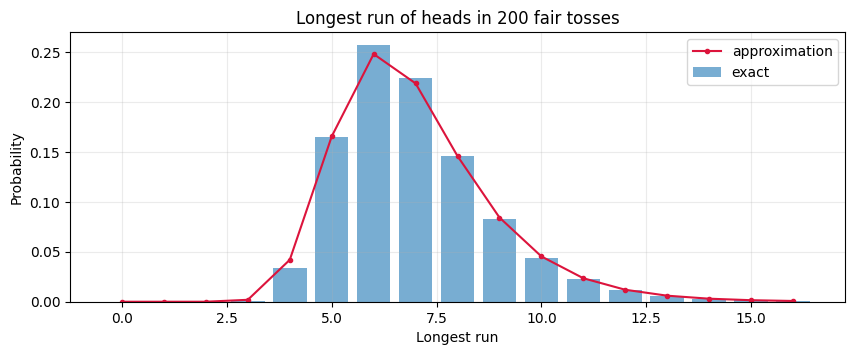

In [2]:
def p_longest_run_at_least(n, r, p):
    """Exact P(longest run of successes >= r) in n independent Bernoulli(p) trials."""
    if r <= 0:
        return 1.0
    state = np.zeros(r)  # state[j]: current run has length j, no run of length r yet
    state[0] = 1.0
    hit = 0.0
    for _ in range(n):
        hit += state[-1] * p
        new = np.empty(r)
        new[0] = state.sum() * (1 - p)
        new[1:] = state[:-1] * p
        state = new
    return hit


def approx_cdf(n, x, p):
    """Extreme-value approximation of P(R_n <= x)."""
    return np.exp(-n * (1 - p) * p ** (x + 1))


# Fair coin, n = 3: Figure 1 / the table on page 197 of the paper.
exact_3 = [p_longest_run_at_least(3, k, 0.5) - p_longest_run_at_least(3, k + 1, 0.5) for k in range(4)]
assert np.allclose(exact_3, [1 / 8, 4 / 8, 2 / 8, 1 / 8])

# Fair coin, n = 200: Table 2 of the paper (exact and approximate columns).
paper_exact = {"0-3": .001, 4: .033, 5: .165, 6: .257, 7: .224, 8: .146, 9: .083, 10: .044, 11: .023, 12: .011, ">12": .012}
paper_approx = {"0-3": .002, 4: .042, 5: .166, 6: .248, 7: .219, 8: .146, 9: .084, 10: .045, 11: .024, 12: .012, ">12": .012}
n, p = 200, 0.5


def exact_pmf(x):
    return p_longest_run_at_least(n, x, p) - p_longest_run_at_least(n, x + 1, p)


mine_exact = {"0-3": 1 - p_longest_run_at_least(n, 4, p), ">12": p_longest_run_at_least(n, 13, p)}
mine_approx = {"0-3": approx_cdf(n, 3, p), ">12": 1 - approx_cdf(n, 12, p)}
for x in range(4, 13):
    mine_exact[x] = exact_pmf(x)
    mine_approx[x] = approx_cdf(n, x, p) - approx_cdf(n, x - 1, p)

print(f"{'x':>5} {'paper exact':>12} {'mine exact':>11} {'paper approx':>13} {'mine approx':>12}")
for key in paper_exact:
    print(f"{key!s:>5} {paper_exact[key]:>12.3f} {mine_exact[key]:>11.3f} {paper_approx[key]:>13.3f} {mine_approx[key]:>12.3f}")
    assert abs(mine_exact[key] - paper_exact[key]) < 6e-4
    assert abs(mine_approx[key] - paper_approx[key]) < 1.5e-3
print("Matches the paper's Table 2.")

xs = np.arange(0, 17)
fig, ax = plt.subplots()
ax.bar(xs, [exact_pmf(x) for x in xs], alpha=0.6, label="exact")
ax.plot(xs, [approx_cdf(n, x, p) - approx_cdf(n, x - 1, p) for x in xs], "o-", color="crimson", markersize=3, label="approximation")
ax.set(title="Longest run of heads in 200 fair tosses", xlabel="Longest run", ylabel="Probability")
ax.legend()
plt.show()

## 2. From counts to coin flips: the run test

1. Take the median of the window counts as a robust "normal level".
2. Mark windows with a count **above** the median as 1, others as 0.
3. Under normal traffic the marks are independent with some probability *p* of being 1:
   - `p_mode="poisson"`: *p* = P(Poisson(median) > median). Most powerful, but assumes Poisson traffic.
   - `p_mode="empirical"`: *p* = the observed share of marked windows. Makes no Poisson assumption.
4. Test statistic: the longest run of 1s. p-value = P(R_n ≥ observed) from section 1.

The demo series has a 30-minute burst of +6 requests/minute on a baseline of 8.

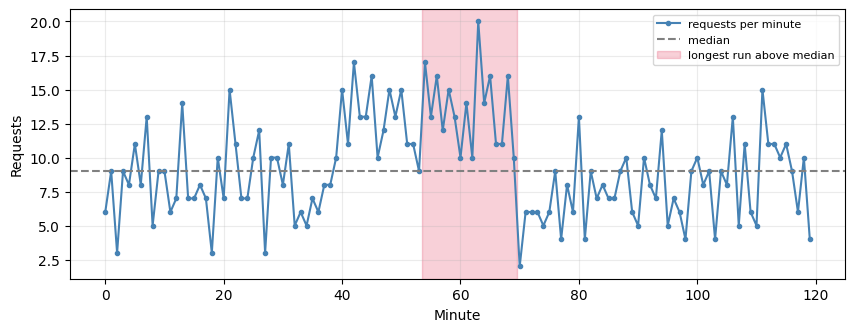

Count test (detect_spikes): flagged windows = []
Run test: longest run = 16 starting at window 54, p = 4.38e-05 (P(above median) = 0.41)


In [3]:
class RunResult(NamedTuple):
    length: int
    start: Optional[int]
    p_value: float
    p_high: float


def longest_run(flags):
    """Length and start index of the longest run of True values."""
    best = best_end = current = 0
    for i, flag in enumerate(flags):
        current = current + 1 if flag else 0
        if current > best:
            best, best_end = current, i
    return best, (best_end - best + 1 if best else None)


def run_test(counts, p_mode="poisson"):
    counts = np.asarray(counts)
    level = np.median(counts)
    above = counts > level
    p_high = poisson.sf(level, level) if p_mode == "poisson" else above.mean()
    length, start = longest_run(above)
    if not 0 < p_high < 1:
        return RunResult(length, start, 1.0, float(p_high))
    return RunResult(length, start, p_longest_run_at_least(len(counts), length, p_high), float(p_high))


def count_test_flags(counts, alpha=0.01):
    return len(detect_spikes(counts, alpha=alpha).flagged) > 0


rng = np.random.default_rng(3)
demo = rng.poisson(8, 120)
demo[40:70] += 6

result = run_test(demo)
spikes = detect_spikes(demo, alpha=0.01)
fig, ax = plt.subplots()
ax.plot(demo, marker="o", markersize=3, color="steelblue", label="requests per minute")
ax.axhline(np.median(demo), color="gray", linestyle="--", label="median")
ax.axvspan(result.start - 0.5, result.start + result.length - 0.5, color="crimson", alpha=0.2, label="longest run above median")
ax.set(xlabel="Minute", ylabel="Requests")
ax.legend(loc="upper right", fontsize=8)
plt.show()
print(f"Count test (detect_spikes): flagged windows = {spikes.flagged}")
print(f"Run test: longest run = {result.length} starting at window {result.start}, p = {result.p_value:.2e} (P(above median) = {result.p_high:.2f})")

## 3. Experiment A: detection power

Poisson baseline of 8 requests/window, 120 windows, a burst starting at window 40. For each burst length and height, estimate how often each test raises an alarm (level 0.01). "Either" = flag if the count test **or** the run test fires.

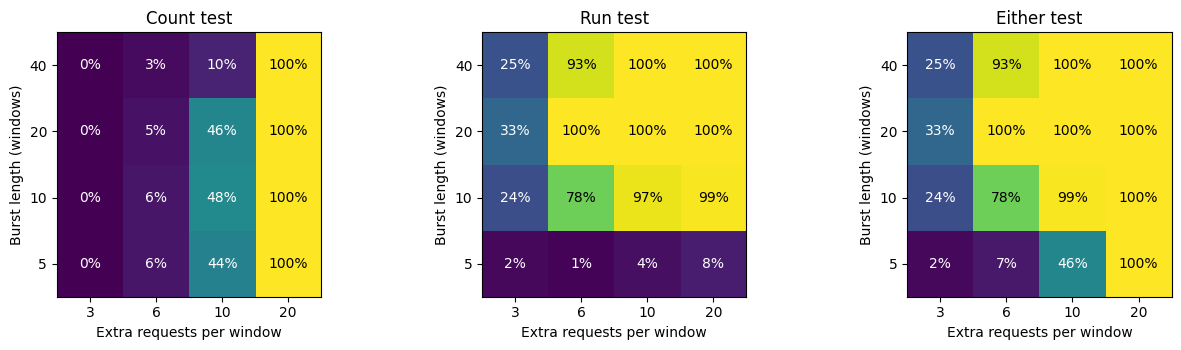

No burst, 300 series: count test 0.3%, run test 1.3%, either 1.7% false alarms


In [4]:
TRIALS = 100
lengths = [5, 10, 20, 40]
extras = [3, 6, 10, 20]
rng = np.random.default_rng(0)

count_power = np.zeros((len(lengths), len(extras)))
run_power = np.zeros_like(count_power)
either_power = np.zeros_like(count_power)
for i, length in enumerate(lengths):
    for j, extra in enumerate(extras):
        hits = np.zeros((TRIALS, 2), dtype=bool)
        for t in range(TRIALS):
            counts = rng.poisson(8, 120)
            counts[40:40 + length] += extra
            hits[t] = count_test_flags(counts), run_test(counts).p_value < 0.01
        count_power[i, j], run_power[i, j] = hits.mean(axis=0)
        either_power[i, j] = hits.any(axis=1).mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, grid, title in zip(axes, (count_power, run_power, either_power), ("Count test", "Run test", "Either test")):
    ax.imshow(grid, vmin=0, vmax=1, cmap="viridis", origin="lower")
    ax.grid(False)
    ax.set(title=title, xticks=range(len(extras)), xticklabels=extras, yticks=range(len(lengths)), yticklabels=lengths,
           xlabel="Extra requests per window", ylabel="Burst length (windows)")
    for i in range(len(lengths)):
        for j in range(len(extras)):
            ax.text(j, i, f"{grid[i, j]:.0%}", ha="center", va="center", color="white" if grid[i, j] < 0.6 else "black")
plt.tight_layout()
plt.show()

null_hits = np.array([
    (count_test_flags(c), run_test(c).p_value < 0.01)
    for c in (rng.poisson(8, 120) for _ in range(300))
])
print(f"No burst, 300 series: count test {null_hits[:, 0].mean():.1%}, run test {null_hits[:, 1].mean():.1%}, either {null_hits.any(axis=1).mean():.1%} false alarms")

**Reading the grid.** The count test needs a *tall* burst (right columns) and does not care about length. The run test needs a *long* burst (upper rows) and is nearly insensitive to height once it is above the median. Their weak spots are opposite: short tall bursts for the run test, long modest ones for the count test.

## 4. Experiment B: false alarms under over-dispersed traffic

Here there is **no burst at all**. The traffic is independent but over-dispersed (negative binomial, same mean 8, variance = dispersion × mean). This is what the dispersion index warns about. How often does each test cry wolf (level 0.01)?

dispersion               count test     run test (Poisson p)   run test (empirical p)
         1                     1.0%                     0.0%                     0.0%
         2                    42.3%                     1.7%                     0.0%
         3                    88.3%                     2.3%                     0.0%


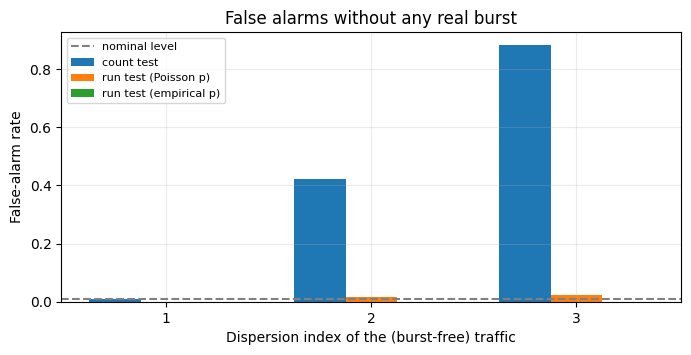

In [5]:
def nb_counts(mean, dispersion, size, rng):
    if dispersion <= 1:
        return rng.poisson(mean, size)
    return rng.negative_binomial(mean / (dispersion - 1), 1 / dispersion, size)


rng = np.random.default_rng(0)
TRIALS_B = 300
dispersions = [1, 2, 3]
labels = ["count test", "run test (Poisson p)", "run test (empirical p)"]
rates = np.zeros((len(dispersions), 3))
for i, d in enumerate(dispersions):
    series = [nb_counts(8, d, 120, rng) for _ in range(TRIALS_B)]
    rates[i] = [
        np.mean([count_test_flags(c) for c in series]),
        np.mean([run_test(c, "poisson").p_value < 0.01 for c in series]),
        np.mean([run_test(c, "empirical").p_value < 0.01 for c in series]),
    ]

print(f"{'dispersion':>10} " + " ".join(f"{label:>24}" for label in labels))
for d, row in zip(dispersions, rates):
    print(f"{d:>10} " + " ".join(f"{value:>24.1%}" for value in row))

fig, ax = plt.subplots(figsize=(8, 3.5))
width = 0.25
for k, label in enumerate(labels):
    ax.bar(np.arange(len(dispersions)) + (k - 1) * width, rates[:, k], width, label=label)
ax.axhline(0.01, color="gray", linestyle="--", label="nominal level")
ax.set(xticks=range(len(dispersions)), xticklabels=dispersions, xlabel="Dispersion index of the (burst-free) traffic",
       ylabel="False-alarm rate", title="False alarms without any real burst")
ax.legend(fontsize=8)
plt.show()

## 5. Takeaways and next steps

- **The paper's distribution works as advertised.** The exact recursion reproduces Table 2, and the closed-form approximation is accurate enough for quick use.
- **The run test closes the gap in the Poisson detector.** Long, modest elevations that the count test almost never flags are caught reliably (Experiment A). Combining the two ("either") covers both short tall bursts and long modest ones.
- **The run test is robust to over-dispersion; the count test is not.** With dispersion ≥ 2 the count test raises false alarms in a large share of burst-free series, while the run test stays near its nominal level, especially with the empirical *p* (Experiment B).

**Caveats**
- Binarizing at the median discards information, so very short bursts are invisible to the run test.
- Windows must be independent; slowly drifting traffic (daily cycle) also produces long runs. Seasonality needs handling first (roadmap).
- Only one threshold (the median) is used; scanning several thresholds would need a multiple-testing correction.
- The test says *that* something is sustained and *where* the longest run is, not the exact start and end of the event.

**Possible next steps**
- Add a `runs` module to the package (exact distribution + `run_test`) with tests, and report it in the CLI.
- Use a detected run to trigger the baseline re-fit (exclude the run windows and re-run `detect_spikes`).
- Mirror the idea for dips (runs *below* the median) and per-status rates (runs of consecutive 5xx requests).